# Entrenamiento de los modelos de Machine Learning — CU8 Generar reportes inteligentes con IA

Este notebook muestra, paso a paso, el entrenamiento de los dos modelos de Machine Learning que usa FashionStore en el **CU8**:

| Modelo | Tipo de aprendizaje | Algoritmo | Endpoint de la app |
|---|---|---|---|
| Predicción de demanda semanal | Supervisado | Regresión lineal (scikit-learn) | `POST /api/reports/ml/predict-demand` |
| Segmentación de clientes (RFM) | No supervisado | K-Means, 3 grupos (scikit-learn) | `POST /api/reports/ml/customer-clusters` |

El notebook reproduce la misma lógica de `backend/app/services/ml/demand_forecast_service.py` y `backend/app/services/ml/customer_segmentation_service.py`: mismas variables, misma separación 80/20, mismos hiperparámetros y mismas métricas.

**Dónde se ejecuta**
- **Google Colab**: Archivo → Subir notebook → Entorno de ejecución → Ejecutar todas. No requiere instalar nada.
- **En la PC**: `pip install numpy pandas scikit-learn matplotlib jupyter` y luego `jupyter notebook docs/ml/entrenamiento_modelos_ml.ipynb`.

**Datos**: por defecto se usan **datos sintéticos** generados con semilla fija (42), idénticos a los que usa la app cuando el negocio todavía no tiene historial suficiente. Son datos de demostración: no representan ventas ni clientes reales. Para entrenar con datos reales, ver la sección *Fuente de datos*.

> La interpretación del texto en lenguaje natural del CU8 usa **Gemini**, un modelo preentrenado por Google; ese modelo no se entrena en este proyecto y por eso no aparece aquí.

In [1]:
from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, silhouette_score
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.figsize"] = (11, 4)

## 1. Fuente de datos

`FUENTE = "sinteticos"` usa los datos de demostración. Para usar datos reales del negocio, exporte desde PostgreSQL los dos CSV siguientes (reemplace `<tenant_id>` por el id de la empresa), súbalos junto al notebook y cambie `FUENTE = "csv"`.

**`ventas.csv`** — unidades vendidas (ventas en caja + pedidos online pagados), mismo filtro que `predict_demand`:
```sql
SELECT s.created_at, si.quantity
FROM sales s JOIN sale_items si ON si.sale_id = s.id
WHERE s.tenant_id = '<tenant_id>' AND s.status = 'completed' AND s.payment_status = 'paid'
UNION ALL
SELECT o.created_at, oi.quantity
FROM orders o JOIN order_items oi ON oi.order_id = o.id
WHERE o.tenant_id = '<tenant_id>' AND o.status = 'paid' AND o.payment_status = 'paid';
```

**`clientes.csv`** — una fila por cliente con su última compra, cantidad de compras y monto total, mismo filtro que `customer_clusters`:
```sql
SELECT user_id, MAX(created_at) AS last_purchase, COUNT(id) AS frequency, SUM(total_amount) AS amount
FROM orders
WHERE tenant_id = '<tenant_id>' AND status = 'paid' AND payment_status = 'paid'
GROUP BY user_id;
```

In [2]:
FUENTE = "sinteticos"   # "sinteticos" o "csv"
SEMILLA = 42            # la misma semilla que usa la app

hoy = date.today()
fin = hoy - timedelta(days=hoy.weekday())   # lunes de la semana actual: las semanas se cuentan hasta aquí
print("Fuente de datos:", FUENTE, "| semana de corte:", fin)

Fuente de datos: sinteticos | semana de corte: 2026-11-09


### Generadores de datos sintéticos

Copia exacta de `backend/app/services/ml/synthetic_data_generator.py`:
- **Ventas semanales**: 64 semanas con tendencia creciente (+0,35 unidades por semana), estacionalidad anual (seno de periodo 52 semanas) y ruido normal.
- **Clientes**: 60 clientes alrededor de tres perfiles (recencia en días, frecuencia de compras, monto gastado): frecuentes de alto gasto, intermedios y ocasionales.

In [3]:
def synthetic_weeks(end, count=64):
    rng = np.random.default_rng(SEMILLA)
    start = end - timedelta(weeks=count)
    return {
        start + timedelta(weeks=i): max(0.0, 100 + 0.35 * i + 24 * np.sin(2 * np.pi * i / 52) + rng.normal(0, 4))
        for i in range(count)
    }


def synthetic_customers():
    rng = np.random.default_rng(SEMILLA)
    centers = [(10, 18, 3000), (75, 6, 650), (200, 1, 90)]
    return [
        tuple(np.maximum([0, 1, 1], rng.normal(center, [8, 1.2, center[2] * 0.12])))
        for center in centers for _ in range(20)
    ]

## 2. Modelo supervisado: predicción de demanda semanal

### 2.1 Datos: unidades vendidas por semana

64 semanas, de 2025-08-18 a 2026-11-02


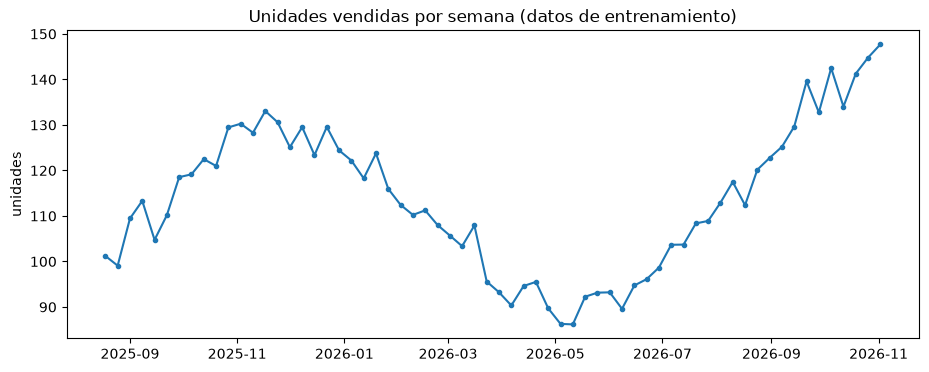

count     64.00
mean     113.73
std       16.01
min       86.18
25%      100.68
50%      112.67
75%      125.14
max      147.70
dtype: float64

In [4]:
if FUENTE == "csv":
    ventas = pd.read_csv("ventas.csv", parse_dates=["created_at"])
    ventas["semana"] = ventas["created_at"].dt.date.map(lambda d: d - timedelta(days=d.weekday()))
    historial = ventas.groupby("semana")["quantity"].sum().to_dict()
    historial = {s: float(v) for s, v in historial.items() if fin - timedelta(weeks=104) <= s < fin}
    inicio = min(historial)
    # las semanas sin ventas cuentan como 0, igual que en la app
    historial = {inicio + timedelta(weeks=i): historial.get(inicio + timedelta(weeks=i), 0.0)
                 for i in range((fin - inicio).days // 7)}
else:
    historial = synthetic_weeks(fin, 64)

serie = pd.Series(historial).sort_index()
print(f"{len(serie)} semanas, de {serie.index[0]} a {serie.index[-1]}")
serie.plot(marker="o", markersize=3, title="Unidades vendidas por semana (datos de entrenamiento)")
plt.ylabel("unidades"); plt.show()
serie.describe().round(2)

### 2.2 Variables de entrada (features)

Para cada semana el modelo recibe 5 variables, igual que `_features` en la app:

| Variable | Significado |
|---|---|
| `indice` | número de semana dentro de la serie (captura la tendencia) |
| `mes` | mes del año |
| `sen_semana`, `cos_semana` | posición de la semana en el año (captura la estacionalidad) |
| `ventas_semana_anterior` | unidades vendidas la semana previa (*lag*) |

La variable objetivo `y` son las unidades vendidas en esa semana. La primera semana se descarta porque no tiene semana anterior.

In [5]:
def features(semana, lag, indice):
    angulo = 2 * np.pi * semana.isocalendar().week / 52
    return [indice, semana.month, np.sin(angulo), np.cos(angulo), lag]


puntos = list(serie.items())
X = np.asarray([features(dia, puntos[i - 1][1], i) for i, (dia, _) in enumerate(puntos) if i])
y = np.asarray([valor for _, valor in puntos[1:]])

tabla = pd.DataFrame(X, columns=["indice", "mes", "sen_semana", "cos_semana", "ventas_semana_anterior"],
                     index=[d for d, _ in puntos[1:]])
tabla["y_unidades"] = y
tabla.head(8).round(3)

,indice,mes,sen_semana,cos_semana,ventas_semana_anterior,y_unidades
2025-08-25,1.0,8.0,-0.885,-0.465,101.219,99.083
2025-09-01,2.0,9.0,-0.935,-0.355,99.083,109.445
2025-09-08,3.0,9.0,-0.971,-0.239,109.445,113.323
2025-09-15,4.0,9.0,-0.993,-0.121,113.323,104.749
2025-09-22,5.0,9.0,-1.000,-0.000,104.749,110.175
2025-09-29,6.0,9.0,-0.993,0.121,110.175,118.526
2025-10-06,7.0,10.0,-0.971,0.239,118.526,119.149
2025-10-13,8.0,10.0,-0.935,0.355,119.149,122.484


### 2.3 Separación entrenamiento / prueba (80 % / 20 %, cronológica)

Las semanas más antiguas (80 %) se usan para entrenar y las más recientes (20 %) para probar. No se mezclan al azar: en una serie de tiempo el modelo no debe ver el futuro durante el entrenamiento.

In [6]:
corte = int(len(y) * 0.8)
X_train, X_test = X[:corte], X[corte:]
y_train, y_test = y[:corte], y[corte:]
print(f"Entrenamiento: {len(y_train)} semanas ({tabla.index[0]} a {tabla.index[corte - 1]})")
print(f"Prueba:        {len(y_test)} semanas ({tabla.index[corte]} a {tabla.index[-1]})")

Entrenamiento: 50 semanas (2025-08-25 a 2026-08-03)
Prueba:        13 semanas (2026-08-10 a 2026-11-02)


### 2.4 Entrenamiento

In [7]:
modelo_demanda = LinearRegression()
modelo_demanda.fit(X_train, y_train)

coeficientes = pd.Series(modelo_demanda.coef_, index=tabla.columns[:-1])
print("Intercepto:", round(modelo_demanda.intercept_, 4))
coeficientes.round(4).to_frame("coeficiente")

Intercepto: 103.1421


,coeficiente
indice,0.4440
mes,0.0624
sen_semana,-14.1779
cos_semana,21.6852
ventas_semana_anterior,-0.0514


### 2.5 Evaluación con las semanas de prueba

- **R²**: qué proporción de la variación de las ventas explica el modelo (1 = perfecto).
- **MSE**: error cuadrático medio, en unidades².

Las predicciones negativas se llevan a 0, igual que en la app.

R²  = 0.790091
MSE = 24.837310
Semanas de prueba = 13


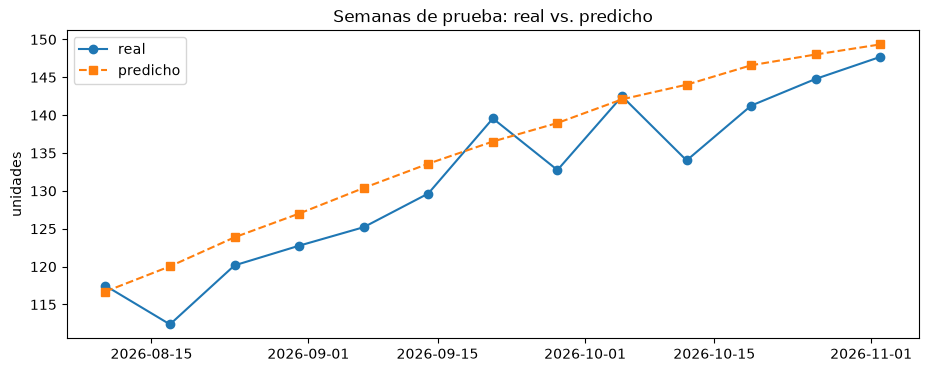

In [8]:
pred_test = np.maximum(0, modelo_demanda.predict(X_test))
mse = float(mean_squared_error(y_test, pred_test))
r2 = float(r2_score(y_test, pred_test))
print(f"R²  = {r2:.6f}")
print(f"MSE = {mse:.6f}")
print(f"Semanas de prueba = {len(y_test)}")

plt.plot(tabla.index[corte:], y_test, "o-", label="real")
plt.plot(tabla.index[corte:], pred_test, "s--", label="predicho")
plt.title("Semanas de prueba: real vs. predicho"); plt.ylabel("unidades"); plt.legend(); plt.show()

### 2.6 Reentrenamiento con todos los datos y pronóstico

Una vez evaluado, el modelo se vuelve a entrenar con todas las semanas y pronostica las próximas semanas (de 1 a 12; aquí 4, el valor por defecto de la app). Cada predicción usa la anterior como `ventas_semana_anterior`. El intervalo de confianza es ±1,96·√MSE.

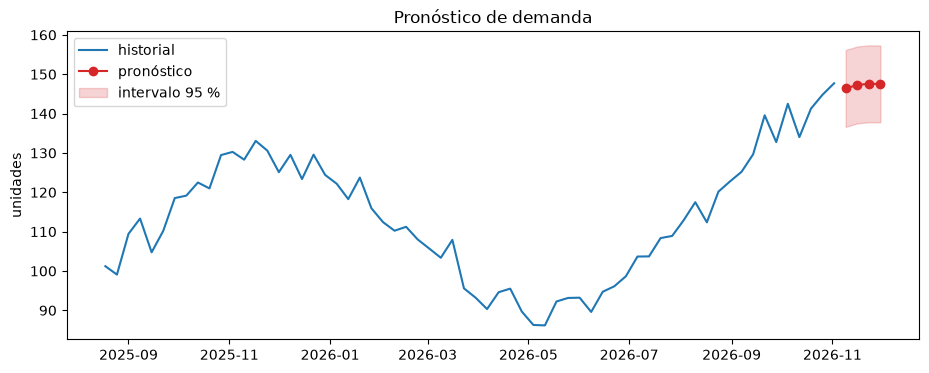

,semana,unidades_predichas,limite_inferior,limite_superior
0,2026-W46,146.38,136.62,156.15
1,2026-W47,147.28,137.51,157.05
2,2026-W48,147.56,137.79,157.33
3,2026-W49,147.53,137.77,157.30


In [9]:
SEMANAS_A_PREDECIR = 4

margen = 1.96 * np.sqrt(mse)
modelo_demanda.fit(X, y)
lag = puntos[-1][1]
pronostico = []
for i in range(SEMANAS_A_PREDECIR):
    semana = fin + timedelta(weeks=i)
    lag = max(0.0, float(modelo_demanda.predict([features(semana, lag, len(puntos) + i)])[0]))
    pronostico.append({"semana": semana.strftime("%G-W%V"), "unidades_predichas": round(lag, 2),
                       "limite_inferior": round(max(0, lag - margen), 2), "limite_superior": round(lag + margen, 2)})
pronostico = pd.DataFrame(pronostico)

semanas_futuras = [fin + timedelta(weeks=i) for i in range(SEMANAS_A_PREDECIR)]
plt.plot(serie.index, serie.values, label="historial")
plt.plot(semanas_futuras, pronostico["unidades_predichas"], "o-", color="tab:red", label="pronóstico")
plt.fill_between(semanas_futuras, pronostico["limite_inferior"], pronostico["limite_superior"],
                 color="tab:red", alpha=0.2, label="intervalo 95 %")
plt.title("Pronóstico de demanda"); plt.ylabel("unidades"); plt.legend(); plt.show()
pronostico

## 3. Modelo no supervisado: segmentación de clientes con K-Means

### 3.1 Datos RFM

Cada cliente se describe con tres valores:
- **Recencia**: días desde su última compra.
- **Frecuencia**: cantidad de compras pagadas.
- **Monto**: total gastado.

Si hay menos de 30 clientes reales, la app completa con los 60 clientes sintéticos; aquí se hace lo mismo.

In [10]:
if FUENTE == "csv":
    cli = pd.read_csv("clientes.csv", parse_dates=["last_purchase"])
    clientes = [(max(0, (hoy - r.last_purchase.date()).days), int(r.frequency), float(r.amount))
                for r in cli.itertuples()]
else:
    clientes = []

sinteticos = synthetic_customers() if len(clientes) < 30 or len(set(clientes)) < 3 else []
rfm = pd.DataFrame(clientes + sinteticos, columns=["recencia_dias", "frecuencia", "monto"])
print(f"Clientes reales: {len(clientes)} | sintéticos: {len(sinteticos)} | total: {len(rfm)}")
rfm.describe().round(2)

Clientes reales: 0 | sintéticos: 60 | total: 60


,recencia_dias,frecuencia,monto
count,60.00,60.00,60.00
mean,94.83,8.34,1254.57
std,79.31,7.11,1294.06
min,3.13,1.00,71.91
25%,15.37,1.85,94.40
50%,73.92,5.56,661.74
75%,192.21,17.05,2888.93
max,217.03,19.47,3406.43


### 3.2 Normalización

Las tres variables tienen escalas muy distintas (días, número de compras, bolivianos). `StandardScaler` las lleva a media 0 y desviación 1 para que ninguna domine la distancia de K-Means.

In [11]:
escalador = StandardScaler()
rfm_escalado = escalador.fit_transform(rfm.values)
pd.DataFrame(rfm_escalado, columns=rfm.columns).describe().round(3)

,recencia_dias,frecuencia,monto
count,60.000,60.000,60.000
mean,0.000,0.000,0.000
std,1.008,1.008,1.008
min,-1.166,-1.041,-0.922
25%,-1.010,-0.921,-0.904
50%,-0.266,-0.395,-0.462
75%,1.238,1.235,1.274
max,1.554,1.578,1.677


### 3.3 Elección del número de grupos

Se prueban de 2 a 6 grupos y se compara la **inercia** (método del codo) y el **silhouette score**. La app usa **3 grupos**.

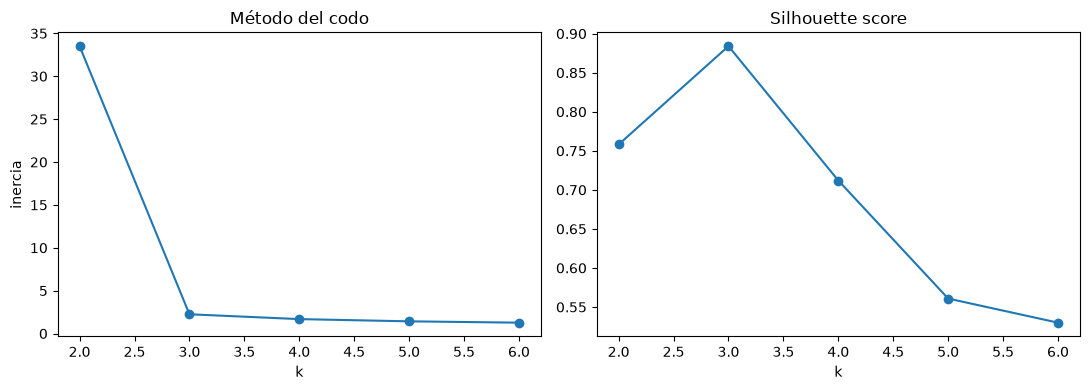

,k,inercia,silhouette
0,2,33.5091,0.7581
1,3,2.2466,0.8840
2,4,1.6830,0.7119
3,5,1.4234,0.5608
4,6,1.2677,0.5300


In [12]:
ks = range(2, 7)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(rfm_escalado)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(rfm_escalado, km.labels_))

fig, (a, b) = plt.subplots(1, 2)
a.plot(list(ks), inercias, "o-"); a.set_title("Método del codo"); a.set_xlabel("k"); a.set_ylabel("inercia")
b.plot(list(ks), siluetas, "o-"); b.set_title("Silhouette score"); b.set_xlabel("k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inercia": inercias, "silhouette": siluetas}).round(4)

### 3.4 Entrenamiento con k = 3

In [13]:
modelo_clientes = KMeans(n_clusters=3, random_state=SEMILLA, n_init=10)
etiquetas = modelo_clientes.fit_predict(rfm_escalado)
silueta = float(silhouette_score(rfm_escalado, etiquetas, sample_size=min(2000, len(rfm)), random_state=SEMILLA))
print(f"Silhouette score = {silueta:.6f}")

Silhouette score = 0.883980


### 3.5 Resultado: segmentos

Los grupos se nombran según su gasto promedio, igual que en la app: el de mayor gasto es *Clientes de alto valor*, luego *valor medio* y *ocasionales*.

                         clientes  gasto_promedio  recencia_promedio  \
segmento                                                               
Clientes de alto valor         20         3030.24              11.45   
Clientes de valor medio        20          644.43              73.35   
Clientes ocasionales           20           89.05             199.70   

                         frecuencia_promedio  
segmento                                      
Clientes de alto valor                 17.92  
Clientes de valor medio                 5.66  
Clientes ocasionales                    1.44  


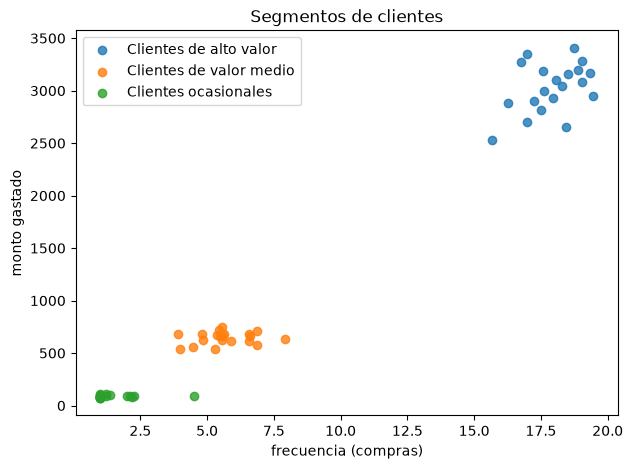

In [14]:
rfm["grupo"] = etiquetas
orden = rfm.groupby("grupo")["monto"].mean().sort_values(ascending=False).index
nombres = dict(zip(orden, ["Clientes de alto valor", "Clientes de valor medio", "Clientes ocasionales"]))
rfm["segmento"] = rfm["grupo"].map(nombres)
rfm["origen"] = ["real"] * len(clientes) + ["sintético"] * len(sinteticos)

resumen = rfm.groupby("segmento").agg(clientes=("monto", "size"), gasto_promedio=("monto", "mean"),
                                      recencia_promedio=("recencia_dias", "mean"),
                                      frecuencia_promedio=("frecuencia", "mean"))
print(resumen.round(2))

fig, ax = plt.subplots(figsize=(7, 5))
for nombre, g in rfm.groupby("segmento"):
    ax.scatter(g["frecuencia"], g["monto"], label=nombre, alpha=0.8)
ax.set_xlabel("frecuencia (compras)"); ax.set_ylabel("monto gastado"); ax.set_title("Segmentos de clientes")
ax.legend(); plt.show()

## 4. Relación con la aplicación

- En la app el entrenamiento ocurre **en el backend (FastAPI), en memoria, cada vez que el administrador solicita el reporte**. No se guarda un archivo de modelo; así cada predicción usa los datos más recientes de la empresa.
- **Predicción de demanda**: `AdminReportsPageComponent` → `predict_demand_route` (`report_routes`) → `predict_demand` sobre las entidades Venta y Pedido (CU8, pasos 3.1 y 3.2 del diagrama de secuencia).
- **Segmentación de clientes**: `AdminReportsPageComponent` → `customer_clusters_route` (`report_routes`) → `customer_clusters` sobre la entidad Pedido (CU8, pasos 4.1 y 4.2).
- La respuesta de ambos endpoints indica si los datos fueron `real`, `mixed` o `synthetic`, con el aviso correspondiente.
- Las pruebas automatizadas de estos modelos están en `backend/tests/test_ml_reports.py`.